In [1]:
from pathlib import Path
from collections import Counter
import concurrent.futures
import multiprocessing
import hashlib
import json
import shutil
import warnings

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import StratifiedGroupKFold

warnings.filterwarnings("ignore")

In [2]:
# =========================================================
# DATASET PATHS
# =========================================================

bananaid_dir = Path(
    "/kaggle/input/datasets/anhnguyen7508/bananaid"
)

bananaimagebd_dir = Path(
    "/kaggle/input/datasets/anhnguyen7508/bananaimagebd"
)

bananaripeness_github_dir = Path(
    "/kaggle/input/datasets/kimlunl/bananaripeness-github"
)

# Ba thư mục dữ liệu độc lập
DATASET_DIRS = {
    "BananaID": bananaid_dir,
    "BananaImageBD": bananaimagebd_dir,
    "BananaRipeness_GitHub": bananaripeness_github_dir,
}

EDA_COUNTS = {"BananaID": 1960, "BananaImageBD": 820, "BananaRipeness_GitHub": 3495}

# Kiểm tra
for name, path in DATASET_DIRS.items():
    if not path.exists():
        raise FileNotFoundError(f"{name}: Không tìm thấy {path}")

    print(f"{name}: {path}")

BananaID: /kaggle/input/datasets/anhnguyen7508/bananaid
BananaImageBD: /kaggle/input/datasets/anhnguyen7508/bananaimagebd
BananaRipeness_GitHub: /kaggle/input/datasets/kimlunl/bananaripeness-github


In [3]:
# =========================================================
# OUTPUT
# =========================================================

WORK_DIR = Path("/kaggle/working")

OUTPUT_DIR = WORK_DIR / "Banana_Merged_Preprocessed"
CLASS_DIR = OUTPUT_DIR / "dataset"

REPORT_DIR = OUTPUT_DIR / "reports"

for directory in [OUTPUT_DIR, CLASS_DIR, REPORT_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

In [4]:
# =========================================================
# CONFIGURATION
# =========================================================

IMAGE_SIZE = 224
SEED = 42

# dHash xám HASH_SIZE x HASH_SIZE bit (16 -> 256 bit). Hash 8x8 (64 bit) quá thô: ảnh nền trắng,
# ít chi tiết cho hash gần như giống nhau -> báo trùng nhầm. 256 bit tách bản sao / ảnh khác rõ hơn.
HASH_SIZE = 16
N_BITS = HASH_SIZE * HASH_SIZE
DUP_THR = 6        # bit khác nhau. Cùng nhãn và <= DUP_THR (~2.3%) -> bản sao, chỉ giữ 1 ảnh
GROUP_THR = 16     # bit khác nhau. Bất kể nhãn và <= GROUP_THR (~6%) -> bắt buộc nằm cùng 1 split
SUSPECT_COLOR_THR = 12     # cặp khác nhãn nhưng độ lệch màu (phân vị 95, thang 0-255) < ngưỡng này -> nghi nhãn sai
DROP_SUSPECT_LABEL_NOISE = False   # chỉ bật sau khi đã xem cross_label_review.png

EXCLUDED_DIR_NAMES = {"augmented", "augmentation", "synthetic", "varying illumination"}
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
CLASS_NAMES = ["Unripe", "Half_Ripe", "Ripe", "Overripe"]

LABEL_MAPPING = {
    # BananaID
    "unripe": "Unripe", "half ripe": "Half_Ripe", "half_ripe": "Half_Ripe",
    "overripe": "Overripe", "ripe": "Ripe",
    # BananaImageBD
    "green": "Unripe", "semi ripe": "Half_Ripe", "semi-ripe": "Half_Ripe", "semi_ripe": "Half_Ripe",
    # BananaRipeness_GitHub
    "class a": "Unripe", "class b": "Half_Ripe", "class c": "Ripe", "class d": "Overripe",
}

## Bước 1. Thu thập + chuẩn hoá nhãn + đối chiếu với EDA

In [5]:
rows, skipped = [], Counter()
for ds, root in DATASET_DIRS.items():
    if not root.exists():
        raise FileNotFoundError(f"{ds}: không thấy {root}")
    for p in root.rglob("*"):
        if not p.is_file() or p.suffix.lower() not in IMAGE_EXTENSIONS:   # .JPG cũng được tính
            continue
        rel_parts = [x.lower() for x in p.relative_to(root).parts[:-1]]
        if any(ex in part for part in rel_parts for ex in EXCLUDED_DIR_NAMES):
            skipped[(ds, "thư mục bị loại")] += 1
            continue
        raw = p.parent.name.lower().strip()
        if raw not in LABEL_MAPPING:
            skipped[(ds, f"nhãn lạ: {raw}")] += 1
            continue
        rows.append({
            "dataset": ds, "path": str(p), "raw_label": raw,
            "label": LABEL_MAPPING[raw],
            "folder": str(p.parent.parent.relative_to(root)),   # để biết ảnh đến từ nhánh nào
        })

df = pd.DataFrame(rows)

print("Đối chiếu với EDA:")
for ds, n_eda in EDA_COUNTS.items():
    n = int((df.dataset == ds).sum())
    print(f"  {ds:24s} notebook={n:5d}  EDA={n_eda:5d}  lệch={n - n_eda:+d}")
print("\nẢnh bị bỏ qua:")
for k, v in skipped.most_common(15):
    print(f"  {k}: {v}")
print("\nNhánh thư mục đã lấy:")
print(df.groupby(["dataset", "folder", "label"]).size().to_string())

Đối chiếu với EDA:
  BananaID                 notebook= 1960  EDA= 1960  lệch=+0
  BananaImageBD            notebook=  820  EDA=  820  lệch=+0
  BananaRipeness_GitHub    notebook= 3494  EDA= 3495  lệch=-1

Ảnh bị bỏ qua:
  ('BananaID', 'thư mục bị loại'): 15750
  ('BananaImageBD', 'thư mục bị loại'): 9870
  ('BananaImageBD', 'nhãn lạ: champa kola'): 994
  ('BananaImageBD', 'nhãn lạ: sagor kola'): 524
  ('BananaImageBD', 'nhãn lạ: sabri kola'): 509
  ('BananaID', 'nhãn lạ: ambon'): 468
  ('BananaImageBD', 'nhãn lạ: bangla kola'): 444
  ('BananaID', 'nhãn lạ: raja'): 424
  ('BananaID', 'nhãn lạ: cavendish'): 380
  ('BananaID', 'nhãn lạ: mas'): 376
  ('BananaID', 'nhãn lạ: saba'): 312

Nhánh thư mục đã lấy:
dataset                folder                                                                                                                                                                                   label    
BananaID               BananaID An image dataset of banana varieties

## Bước 2. Đọc mỗi ảnh 1 lần: MD5 + dHash xám 256 bit + thumbnail màu 16x16

In [6]:
def extract(path):
    try:
        data = Path(path).read_bytes()
        bgr = cv2.imdecode(np.frombuffer(data, np.uint8), cv2.IMREAD_COLOR)
        if bgr is None:
            return None
        rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
        gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
        g = cv2.resize(gray, (HASH_SIZE + 1, HASH_SIZE), interpolation=cv2.INTER_AREA)
        dhash = (g[:, 1:] > g[:, :-1]).flatten()                        # N_BITS bit
        thumb = cv2.resize(rgb, (16, 16), interpolation=cv2.INTER_AREA)  # để so màu
        h, w = rgb.shape[:2]
        return hashlib.md5(data).hexdigest(), dhash, thumb, w, h
    except Exception:
        return None

n_cores = multiprocessing.cpu_count()
print(f"Dùng {n_cores} cores")
with concurrent.futures.ProcessPoolExecutor(max_workers=n_cores) as ex:
    res = list(tqdm(ex.map(extract, df["path"].tolist(), chunksize=32), total=len(df)))

ok = np.array([r is not None for r in res])
print(f"Ảnh đọc lỗi: {(~ok).sum()}")
df = df[ok].reset_index(drop=True)
res = [r for r in res if r is not None]
df["md5"] = [r[0] for r in res]
df["w"] = [r[3] for r in res]
df["h"] = [r[4] for r in res]
H = np.stack([r[1] for r in res])      # (n, N_BITS) bool
T = np.stack([r[2] for r in res])      # (n, 16, 16, 3) uint8
del res
print("Sau khi đọc:", len(df), "ảnh")

Dùng 4 cores


  0%|          | 0/6274 [00:00<?, ?it/s]

Ảnh đọc lỗi: 0
Sau khi đọc: 6274 ảnh


## Bước 3. Loại trùng lặp
- MD5 trùng mà khác nhãn: xoá hết nhóm (không biết nhãn nào đúng).
- MD5 trùng cùng nhãn: giữ 1.
- dHash gần giống **và cùng nhãn**: giữ 1 (ảnh độ phân giải cao nhất). Kết quả không phụ thuộc thứ tự quét.
- dHash gần giống nhưng **khác nhãn**: không xoá tự động, xuất ra để xem tay.

In [7]:
removed_log = []

def drop_rows(mask, reason):
    """mask=True là loại. Lọc df, H, T đồng bộ và ghi log."""
    global df, H, T
    mask = np.asarray(mask, bool)
    if mask.any():
        removed_log.append(df.loc[mask, ["dataset", "path", "label", "md5"]].assign(reason=reason))
    df = df[~mask].reset_index(drop=True)
    H, T = H[~mask], T[~mask]
    print(f"  {reason:24s} loại {int(mask.sum()):5d} -> còn {len(df)}")

def hamming_pairs(H, max_bits):
    """Trả về (i, j, số bit khác) cho mọi cặp i<j có khoảng cách <= max_bits."""
    nn = NearestNeighbors(radius=max_bits / H.shape[1] + 1e-9, metric="hamming",
                          algorithm="brute", n_jobs=-1).fit(H)
    dist, idx = nn.radius_neighbors(H)
    I, J, D = [], [], []
    for i, (d, nb) in enumerate(zip(dist, idx)):
        m = nb > i
        I.append(np.full(int(m.sum()), i)); J.append(nb[m])
        D.append(np.rint(d[m] * H.shape[1]).astype(int))
    return np.concatenate(I), np.concatenate(J), np.concatenate(D)

def components(n, I, J):
    """Union-find: trả về id cụm cho từng ảnh."""
    parent = list(range(n))
    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x
    for a, b in zip(I, J):
        ra, rb = find(a), find(b)
        if ra != rb:
            parent[rb] = ra
    return np.array([find(i) for i in range(n)])

print("Loại trùng:")
# 3.1 MD5
n_lab = df.groupby("md5")["label"].transform("nunique").values
drop_rows(n_lab > 1, "md5_trung_khac_nhan")
drop_rows(df.duplicated("md5").values, "md5_trung_cung_nhan")

# 3.2 dHash, chỉ cùng nhãn
I, J, D = hamming_pairs(H, DUP_THR)
lab = df["label"].values
same = lab[I] == lab[J]
comp = components(len(df), I[same], J[same])
order = pd.DataFrame({"comp": comp, "area": (df.w * df.h).values}).sort_values(
    ["comp", "area"], ascending=[True, False], kind="stable")
keep_idx = order.drop_duplicates("comp").index.values
drop_rows(~np.isin(np.arange(len(df)), keep_idx), "near_dup_cung_nhan")

Loại trùng:
  md5_trung_khac_nhan      loại     4 -> còn 6270
  md5_trung_cung_nhan      loại    11 -> còn 6259
  near_dup_cung_nhan       loại    26 -> còn 6233


Cặp gần giống khác nhãn: 2  | nghi nhãn sai (màu gần như y hệt): 1


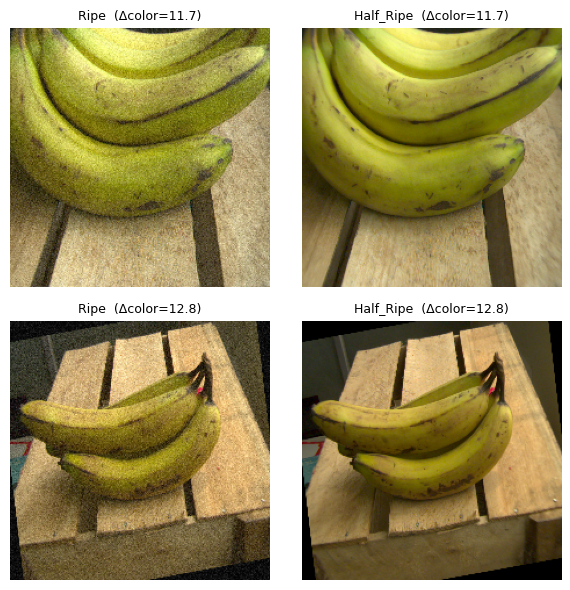

In [8]:
# 3.3 Cặp gần giống nhưng KHÁC nhãn -> báo cáo, không tự xoá
I, J, D = hamming_pairs(H, DUP_THR)
lab = df["label"].values
cr = lab[I] != lab[J]
I, J, D = I[cr], J[cr], D[cr]
# Độ lệch màu = phân vị 95 của |chênh lệch| theo từng pixel thumbnail. KHÔNG dùng trung bình cả ảnh:
# nền trắng chiếm phần lớn nên trung bình làm loãng sự khác biệt giữa quả xanh và quả chín.
if len(I):
    pix_diff = np.abs(T[I].astype(int) - T[J].astype(int)).mean(axis=3).reshape(len(I), -1)
    color_diff = np.percentile(pix_diff, 95, axis=1)
else:
    color_diff = np.array([])

cross_df = pd.DataFrame({
    "path_a": df.path.values[I], "path_b": df.path.values[J],
    "dataset_a": df.dataset.values[I], "dataset_b": df.dataset.values[J],
    "label_a": lab[I], "label_b": lab[J],
    "hamming": D, "color_diff": color_diff,
})
cross_df["suspect_noise"] = cross_df.color_diff < SUSPECT_COLOR_THR
cross_df.sort_values("color_diff").to_csv(REPORT_DIR / "cross_label_pairs.csv", index=False)
print(f"Cặp gần giống khác nhãn: {len(cross_df)}  | nghi nhãn sai (màu gần như y hệt): {int(cross_df.suspect_noise.sum())}")

# Lưới ảnh để xem tay: 8 cặp màu giống nhất
top = cross_df.sort_values("color_diff").head(8)
if len(top):
    fig, axes = plt.subplots(len(top), 2, figsize=(6, 3 * len(top)))
    axes = np.atleast_2d(axes)
    for r, (_, row) in enumerate(top.iterrows()):
        for c, (pth, lb) in enumerate([(row.path_a, row.label_a), (row.path_b, row.label_b)]):
            axes[r, c].imshow(cv2.cvtColor(cv2.imread(pth), cv2.COLOR_BGR2RGB))
            axes[r, c].set_title(f"{lb}  (Δcolor={row.color_diff:.1f})", fontsize=9)
            axes[r, c].axis("off")
    plt.tight_layout()
    plt.savefig(REPORT_DIR / "cross_label_review.png", dpi=110)
    plt.show()

if DROP_SUSPECT_LABEL_NOISE and len(cross_df):
    bad = set(I[color_diff < SUSPECT_COLOR_THR]) | set(J[color_diff < SUSPECT_COLOR_THR])
    drop_rows(np.isin(np.arange(len(df)), list(bad)), "nghi_nhan_sai")

## Bước 4. Gom nhóm ảnh gần giống (bất kể nhãn) để chia tập không rò rỉ

In [9]:
I, J, D = hamming_pairs(H, GROUP_THR)
df["group"] = components(len(df), I, J)
gsize = df["group"].value_counts()
cross_ds = int((df.groupby("group")["dataset"].nunique() > 1).sum())
print(f"Số ảnh: {len(df)} | số nhóm: {len(gsize)} | nhóm có >=2 ảnh: {(gsize >= 2).sum()}")
print(f"Nhóm lớn nhất: {gsize.iloc[0]} ảnh ({gsize.iloc[0] / len(df):.1%}) | nhóm trải nhiều dataset: {cross_ds}")
if gsize.iloc[0] / len(df) > 0.03:
    print(f"CẢNH BÁO: có nhóm quá lớn (do nối chuỗi A~B~C). Hạ GROUP_THR (đang {GROUP_THR}/{N_BITS} bit) rồi chạy lại.")

Số ảnh: 6233 | số nhóm: 6036 | nhóm có >=2 ảnh: 176
Nhóm lớn nhất: 7 ảnh (0.1%) | nhóm trải nhiều dataset: 0


## Bước 5. Chia train / val / test theo nhóm, stratified theo (nhãn, dataset)

In [10]:
y = (df.label + "|" + df.dataset).values
groups = df.group.values

def take_fold(pool, n_splits):
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    tr, te = next(sgkf.split(np.zeros(len(pool)), y[pool], groups[pool]))
    return pool[tr], pool[te]

all_idx = np.arange(len(df))
rest_idx, test_idx = take_fold(all_idx, 7)     # test ~ 1/7  = 14.3%
train_idx, val_idx = take_fold(rest_idx, 6)    # val  ~ 1/6 của 6/7 = 14.3%, train ~ 71.4%

df["split"] = ""
df.loc[train_idx, "split"] = "train"
df.loc[val_idx, "split"] = "val"
df.loc[test_idx, "split"] = "test"

# Kiểm chứng: không có nhóm/MD5 nào nằm ở 2 split
g_split = df.groupby("group")["split"].nunique()
m_split = df.groupby("md5")["split"].nunique()
assert (g_split == 1).all() and (m_split == 1).all(), "Rò rỉ giữa các split!"

# Khoảng cách dHash nhỏ nhất từ mỗi ảnh val/test tới tập train
nn = NearestNeighbors(n_neighbors=1, metric="hamming", algorithm="brute").fit(H[train_idx])
for name, idx in [("val", val_idx), ("test", test_idx)]:
    d = nn.kneighbors(H[idx])[0][:, 0] * N_BITS
    print(f"{name}: khoảng cách tới train gần nhất  min={d.min():.0f}  p5={np.percentile(d, 5):.0f}  median={np.median(d):.0f}")
    assert d.min() > GROUP_THR, f"{name} còn ảnh gần giống train"

print("\nSplit x Label:")
print(pd.crosstab(df.split, df.label)[CLASS_NAMES].loc[["train", "val", "test"]])
print("\nSplit x Dataset:")
print(pd.crosstab(df.split, df.dataset).loc[["train", "val", "test"]])

val: khoảng cách tới train gần nhất  min=17  p5=22  median=47
test: khoảng cách tới train gần nhất  min=17  p5=22  median=47

Split x Label:
label  Unripe  Half_Ripe  Ripe  Overripe
split                                   
train    1456       1073   966       954
val       291        212   194       190
test      293        217   196       191

Split x Dataset:
dataset  BananaID  BananaImageBD  BananaRipeness_GitHub
split                                                  
train        1399            580                   2470
val           278            116                    493
test          283            115                    499


## Bước 6. Kiểm tra việc gộp nhãn có hợp lý không
Hue trung bình (độ, chỉ tính pixel đủ bão hoà) theo dataset x nhãn.
Mong đợi trong **mỗi dataset**: Unripe > Half_Ripe > Ripe > Overripe.

In [11]:
def banana_hue(thumb):
    hsv = cv2.cvtColor(thumb, cv2.COLOR_RGB2HSV)
    m = (hsv[..., 1] > 60) & (hsv[..., 2] > 50)
    return hsv[..., 0][m].mean() * 2 if m.sum() >= 8 else np.nan

df["hue"] = [banana_hue(t) for t in T]
hue_table = df.pivot_table(index="dataset", columns="label", values="hue", aggfunc="mean")[CLASS_NAMES].round(1)
print(hue_table)
hue_table.to_csv(REPORT_DIR / "hue_by_dataset_label.csv")
for ds, r in hue_table.iterrows():
    print(f"  {ds:24s} đơn điệu giảm: {bool(r.is_monotonic_decreasing)}")

label                  Unripe  Half_Ripe  Ripe  Overripe
dataset                                                 
BananaID                 65.8       56.2  46.0      39.5
BananaImageBD            83.5       52.6  44.5      40.2
BananaRipeness_GitHub    95.0       62.6  48.7      46.5
  BananaID                 đơn điệu giảm: True
  BananaImageBD            đơn điệu giảm: True
  BananaRipeness_GitHub    đơn điệu giảm: True


## Bước 7. Pad replicate biên + resize + lưu PNG

In [12]:
def pad_square_replicate(rgb):
    h, w = rgb.shape[:2]
    s = max(h, w)
    top, left = (s - h) // 2, (s - w) // 2
    return cv2.copyMakeBorder(rgb, top, s - h - top, left, s - w - left, cv2.BORDER_REPLICATE)

for split in ["train", "val", "test"]:
    for c in CLASS_NAMES:
        (CLASS_DIR / split / c).mkdir(parents=True, exist_ok=True)

out_paths = []
for _, r in tqdm(df.iterrows(), total=len(df), desc="Lưu ảnh"):
    bgr = cv2.imread(r.path, cv2.IMREAD_COLOR)
    rgb = pad_square_replicate(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
    if rgb.shape[0] != IMAGE_SIZE:
        rgb = cv2.resize(rgb, (IMAGE_SIZE, IMAGE_SIZE), interpolation=cv2.INTER_AREA)
    dest = CLASS_DIR / r.split / r.label / f"{r.dataset}_{r.md5[:12]}.png"
    cv2.imwrite(str(dest), cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_PNG_COMPRESSION, 3])
    out_paths.append(str(dest))
df["out_path"] = out_paths

Lưu ảnh:   0%|          | 0/6233 [00:00<?, ?it/s]

## Bước 8. Thống kê từ tập train (mean/std, class weight) + báo cáo

In [13]:
s, s2, n_px = np.zeros(3), np.zeros(3), 0
for pth in tqdm(df.loc[df.split == "train", "out_path"], desc="mean/std train"):
    a = cv2.cvtColor(cv2.imread(pth), cv2.COLOR_BGR2RGB).reshape(-1, 3) / 255.0
    s += a.sum(0); s2 += (a ** 2).sum(0); n_px += len(a)
mean = s / n_px
std = np.sqrt(s2 / n_px - mean ** 2)

cnt = df[df.split == "train"].label.value_counts()
class_weight = {c: float(len(df[df.split == "train"]) / (len(CLASS_NAMES) * cnt[c])) for c in CLASS_NAMES}

stats = {"class_names": CLASS_NAMES, "image_size": IMAGE_SIZE,
         "mean_rgb": mean.round(4).tolist(), "std_rgb": std.round(4).tolist(),
         "class_weight_train": {k: round(v, 3) for k, v in class_weight.items()},
         "n_train": int((df.split == "train").sum()), "n_val": int((df.split == "val").sum()),
         "n_test": int((df.split == "test").sum())}
(REPORT_DIR / "dataset_stats.json").write_text(json.dumps(stats, indent=2, ensure_ascii=False))
print(json.dumps(stats, indent=2, ensure_ascii=False))

# Bảng trước / sau dedup theo dataset (dùng cho phần "Mô tả dataset")
removed = pd.concat(removed_log) if removed_log else pd.DataFrame(columns=["dataset", "reason"])
removed.to_csv(REPORT_DIR / "removed_images.csv", index=False)
summary = pd.DataFrame({"thu_thap": pd.Series(Counter(pd.DataFrame(rows).dataset)),
                        "con_lai": df.dataset.value_counts()}).fillna(0).astype(int)
if len(removed):
    summary = summary.join(removed.pivot_table(index="dataset", columns="reason", values="path", aggfunc="count").fillna(0).astype(int))
summary.to_csv(REPORT_DIR / "summary_before_after.csv")
print(summary)

df.drop(columns=["hue"]).to_csv(REPORT_DIR / "final_dataset_split_mapping.csv", index=False)
print("\nXong. Dataset:", CLASS_DIR)

mean/std train:   0%|          | 0/4449 [00:00<?, ?it/s]

{
  "class_names": [
    "Unripe",
    "Half_Ripe",
    "Ripe",
    "Overripe"
  ],
  "image_size": 224,
  "mean_rgb": [
    0.5289,
    0.5297,
    0.4402
  ],
  "std_rgb": [
    0.2538,
    0.2464,
    0.2919
  ],
  "class_weight_train": {
    "Unripe": 0.764,
    "Half_Ripe": 1.037,
    "Ripe": 1.151,
    "Overripe": 1.166
  },
  "n_train": 4449,
  "n_val": 887,
  "n_test": 897
}
                       thu_thap  con_lai  md5_trung_cung_nhan  \
BananaID                   1960     1960                  NaN   
BananaImageBD               820      811                  0.0   
BananaRipeness_GitHub      3494     3462                 11.0   

                       md5_trung_khac_nhan  near_dup_cung_nhan  
BananaID                               NaN                 NaN  
BananaImageBD                          2.0                 7.0  
BananaRipeness_GitHub                  2.0                19.0  

Xong. Dataset: /kaggle/working/Banana_Merged_Preprocessed/dataset
